## Library Installation

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.applications.efficientnet import preprocess_input

# Configure GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✓ GPU memory growth enabled for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(f"GPU configuration error: {e}")

import matplotlib.pyplot as plt
import seaborn as sns
import gc 
import random
import numpy as np
import os
import shutil
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.spatial.distance import cdist

sns.set_style('whitegrid')
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

✓ GPU memory growth enabled for 1 GPU(s)
TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Path Configuration

In [2]:
# Proyect Path
MAIN_PATH = './Part-1'
# Base path of your dataset
BASE_PATH = MAIN_PATH + '/dataset'

if os.path.exists(BASE_PATH):
    print(f"✓ Path found: {BASE_PATH}")
    print(f"Available folders: {os.listdir(BASE_PATH)}")
else:
    print(f"✗ Path not found. Please adjust BASE_PATH")

✓ Path found: ./Part-1/dataset
Available folders: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow', 'volcanos']


## Hyperparameter Configuration

In [35]:
CONFIG = {
    'IMG_SIZE': (224, 224),
    'BATCH_SIZE': 16,
    'EPOCHS': 20,
    'LEARNING_RATE': 0.001,
    'VALIDATION_SPLIT': 0.2,
    'SEED': 42,
    'NUM_EXPERTS': 6,   
    'THRESHOLD': 0.8
}

np.random.seed(CONFIG['SEED'])
tf.random.set_seed(CONFIG['SEED'])

print("Model configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Model configuration:
  IMG_SIZE: (224, 224)
  BATCH_SIZE: 16
  EPOCHS: 20
  LEARNING_RATE: 0.001
  VALIDATION_SPLIT: 0.2
  SEED: 42
  NUM_EXPERTS: 6
  THRESHOLD: 0.8


## Dataset Preparation and Exploration

✓ Balanced dataset already exists: ./Part-1/dataset_balanced


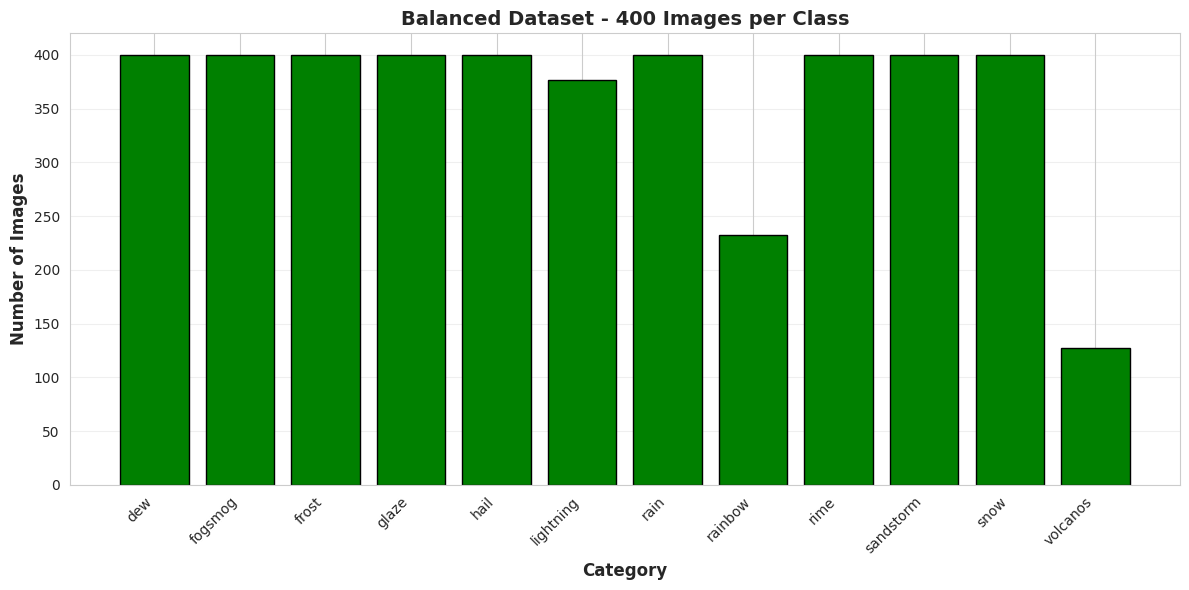

Found 3470 images belonging to 12 classes.
Found 866 images belonging to 12 classes.


In [4]:
def create_balanced_dataset(base_path, max_samples_per_class=100):
    """
    Creates a balanced dataset by copying max X images per category
    """

    balanced_path = base_path + "_balanced"

    if os.path.exists(balanced_path):
        print(f"✓ Balanced dataset already exists: {balanced_path}")
        return balanced_path

    os.makedirs(balanced_path)

    categories = [d for d in os.listdir(base_path)
                 if os.path.isdir(os.path.join(base_path, d))]

    for category in categories:
        category_path = os.path.join(base_path, category)
        balanced_category_path = os.path.join(balanced_path, category)
        os.makedirs(balanced_category_path, exist_ok=True)

        images = [f for f in os.listdir(category_path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        if len(images) > max_samples_per_class:
            selected_images = np.random.choice(images, max_samples_per_class, replace=False)
        else:
            selected_images = images

        for img in selected_images:
            src = os.path.join(category_path, img)
            dst = os.path.join(balanced_category_path, img)
            shutil.copy2(src, dst)

        print(f"✓ {category}: {len(selected_images)} images")

    print(f"\nBalanced dataset created at: {balanced_path}")
    return balanced_path

BALANCED_PATH = create_balanced_dataset(BASE_PATH, max_samples_per_class=400)
BASE_PATH = BALANCED_PATH

def explore_dataset_balanced(base_path):
    """Explores the balanced dataset"""

    categories = [d for d in os.listdir(base_path)
                  if os.path.isdir(os.path.join(base_path, d))]

    data = []
    total_images = 0

    for category in sorted(categories):
        category_path = os.path.join(base_path, category)
        images = [f for f in os.listdir(category_path)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        num_images = len(images)
        total_images += num_images

        data.append({
            'Category': category,
            'Number of images': num_images
        })

    df = pd.DataFrame(data)

    plt.figure(figsize=(12, 6))
    plt.bar(df['Category'], df['Number of images'], color='green', edgecolor='black')
    plt.xlabel('Category', fontsize=12, fontweight='bold')
    plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
    plt.title('Balanced Dataset - 400 Images per Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    return df, categories

df_distribution, CATEGORIES = explore_dataset_balanced(BASE_PATH)
NUM_CLASSES = len(CATEGORIES)



train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,

    validation_split=CONFIG['VALIDATION_SPLIT']
)

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=CONFIG['VALIDATION_SPLIT']
)

train_generator = train_datagen.flow_from_directory(
    BASE_PATH,
    target_size=CONFIG['IMG_SIZE'],
    batch_size=CONFIG['BATCH_SIZE'],
    class_mode='categorical',
    subset='training',
    seed=CONFIG['SEED'],
    shuffle=True
)

validation_generator = validation_datagen.flow_from_directory(
    BASE_PATH,
    target_size=CONFIG['IMG_SIZE'],
    batch_size=CONFIG['BATCH_SIZE'],
    class_mode='categorical',
    subset='validation',
    seed=CONFIG['SEED'],
    shuffle=False
)

## Model Building Using Transfer Learning

In [5]:
def build_moe_model(num_classes, img_size, num_experts=3):
    """
    Builds a fully exportable MoE CNN model without Lambda layers.
    This architecture is 100% native to Keras, ensuring safe and easy 
    saving/loading across different environments.
    """
    # 1. Define the input explicitly
    inputs = layers.Input(shape=(*img_size, 3))

    # 2. Instantiate base model using input_shape 
    base_model = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(*img_size, 3)
    )
    base_model.trainable = False

    # 3. Call the base model
    x = base_model(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    shared_features = layers.BatchNormalization()(x)

    # 4. Create the Experts
    expert_outputs_expanded = []
    for i in range(num_experts):
        e = layers.Dense(512, activation='relu', name=f'expert_{i}_dense1')(shared_features)
        e = layers.Dropout(0.5)(e)
        e = layers.BatchNormalization()(e)
        
        e = layers.Dense(256, activation='relu', name=f'expert_{i}_dense2')(e)
        e = layers.Dropout(0.3)(e)
        
        # Expert output (logits). Shape: (batch_size, num_classes)
        e_out = layers.Dense(num_classes, activation='linear', name=f'expert_{i}_out')(e)
        
        # TRICK 1: Expand dimensions using native Reshape layer
        # We convert the shape to (batch_size, num_classes, 1) so we can stack them
        e_exp = layers.Reshape((num_classes, 1), name=f'expert_{i}_reshape')(e_out)
        expert_outputs_expanded.append(e_exp)

    # TRICK 2: Join experts using Concatenate (Native Keras)
    # Stacks all experts along the last axis.
    # Resulting shape: (batch_size, num_classes, num_experts)
    stacked_experts = layers.Concatenate(axis=2, name='concat_experts')(expert_outputs_expanded)

    # 5. Independent Gating Network (using sigmoid for your multilabel theory)
    # Resulting shape: (batch_size, num_experts)
    gate = layers.Dense(num_experts, activation='sigmoid', name='gating_network')(shared_features)

    # TRICK 3: The magic of layers.Dot
    # This multiplies the experts by the gate weights and sums the results automatically.
    # 'axes=(2, 1)' tells Keras: align axis 2 of stacked_experts with axis 1 of gate.
    # Automatic output shape: (batch_size, num_classes)
    weighted_expert_output = layers.Dot(axes=(2, 1), name='dot_experts_gate')([stacked_experts, gate])

    # 6. Final Activation with SIGMOID (independent multi-label predictions)
    final_output = layers.Activation('sigmoid', name='final_output')(weighted_expert_output)

    # 7. Build the final model
    model = models.Model(inputs=inputs, outputs=final_output)

    return model
model=build_moe_model(num_classes=NUM_CLASSES, img_size=CONFIG['IMG_SIZE'], num_experts=CONFIG['NUM_EXPERTS'])
model.summary()


I0000 00:00:1773023036.020086   14913 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5578 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ input_layer[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_0_dense1     │ (None, 512)       │    655,872 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_1_dense1     │ (None, 512)       │    655,872 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_2_dense1     │ (None, 512)       │    655,872 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_3_dense1     │ (None, 512)       │    655,872 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_4_dense1     │ (None, 512)       │    655,872 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expert_5_dense1     │ (None, 512)       │    655,872 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ expert_0_dense1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 512)       │          0 │ expert_1_dense1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 512)       │          0 │ expert_2_dense1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 512)       │          0 │ expert_3_dense1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 512)       │          0 │ expert_4_dense1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 512)       │          0 │ expert_5_dense1[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dropout[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dropout_2[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 8,816,369 (33.63 MB)

 Trainable params: 4,758,094 (18.15 MB)

 Non-trainable params: 4,058,275 (15.48 MB)

## Model Compilation

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['LEARNING_RATE']),
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

## Training Callbacks

In [7]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        monitor='val_loss',
        save_best_only=True,
        verbose=1,
        filepath=MAIN_PATH + '/models/MoE/moe_model.keras'
    )
]

## Training with Frozen Base Layers

In [8]:
history_phase1 = model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1773023080.438615   15023 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.5463 - loss: 0.2480 - precision: 0.4921 - recall: 0.5060
Epoch 1: val_loss improved from None to 0.07653, saving model to ./Part-1/models/MoE/moe_model.keras
217/217 ━━━━━━━━━━━━━━━━━━━━ 102s 309ms/step - accuracy: 0.6960 - loss: 0.1535 - precision: 0.6734 - recall: 0.6251 - val_accuracy: 0.8591 - val_loss: 0.0765 - val_precision: 0.8120 - val_recall: 0.8730 - learning_rate: 0.0010
Epoch 2/20
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8453 - loss: 0.0777 - precision: 0.8635 - recall: 0.7815
Epoch 2: val_loss improved from 0.07653 to 0.07139, saving model to ./Part-1/models/MoE/moe_model.keras
217/217 ━━━━━━━━━━━━━━━━━━━━ 23s 107ms/step - accuracy: 0.8438 - loss: 0.0789 - precision: 0.8625 - recall: 0.7827 - val_accuracy: 0.8684 - val_loss: 0.0714 - val_precision: 0.8166 - val_recall: 0.8949 - learning_rate: 0.0010
Epoch 3/20
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.8779 - loss: 0.0646 - precision: 0.88

## Training History (Both Phases)

In [9]:
history = {
    'accuracy': history_phase1.history['accuracy'] ,
    'val_accuracy': history_phase1.history['val_accuracy'],
    'loss': history_phase1.history['loss'],
    'val_loss': history_phase1.history['val_loss'],
    'precision': history_phase1.history['precision'],
    'val_precision': history_phase1.history['val_precision'],
    'recall': history_phase1.history['recall'],
    'val_recall': history_phase1.history['val_recall']
}

## Training Results Visualization

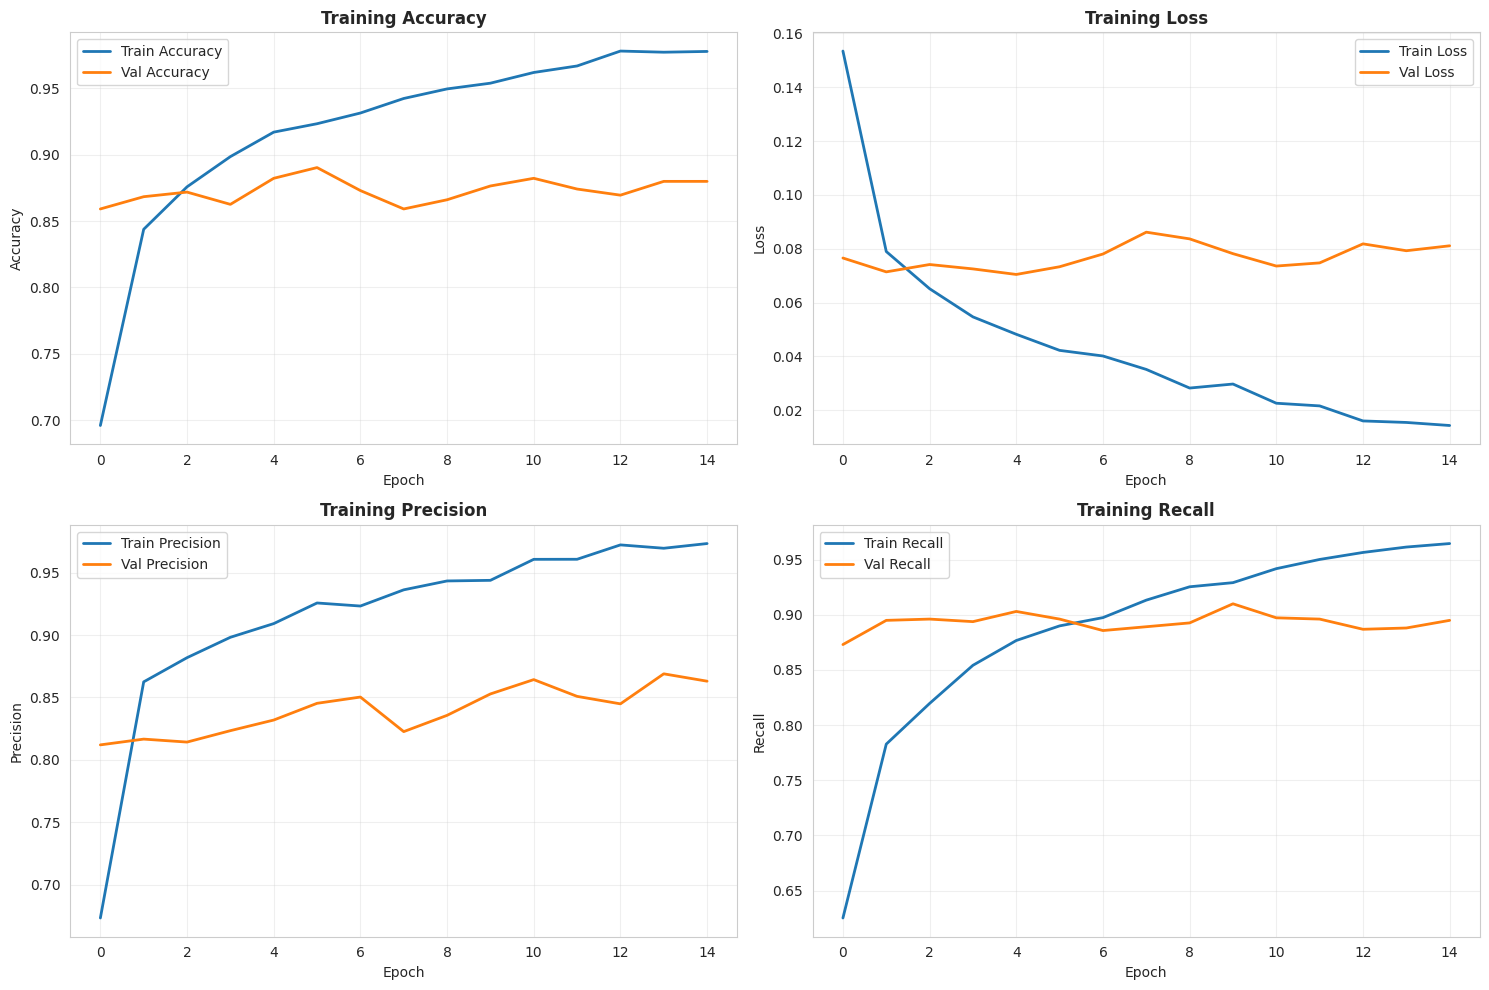

In [10]:
def plot_training_history(history):
    """Visualizes training metrics"""

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    axes[0, 0].plot(history['accuracy'], label='Train Accuracy', linewidth=2)
    axes[0, 0].plot(history['val_accuracy'], label='Val Accuracy', linewidth=2)
    axes[0, 0].set_title('Training Accuracy', fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    axes[0, 1].plot(history['loss'], label='Train Loss', linewidth=2)
    axes[0, 1].plot(history['val_loss'], label='Val Loss', linewidth=2)
    axes[0, 1].set_title('Training Loss', fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    axes[1, 0].plot(history['precision'], label='Train Precision', linewidth=2)
    axes[1, 0].plot(history['val_precision'], label='Val Precision', linewidth=2)
    axes[1, 0].set_title('Training Precision', fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Precision')
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    axes[1, 1].plot(history['recall'], label='Train Recall', linewidth=2)
    axes[1, 1].plot(history['val_recall'], label='Val Recall', linewidth=2)
    axes[1, 1].set_title('Training Recall', fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Recall')
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_history(history)

## Validation Set Evaluation

In [11]:
# Saving model into a tf format to use in a production environment
model.export(MAIN_PATH + '/models/MoE/moe_model')

INFO:tensorflow:Assets written to: ./Part-1/models/MoE/moe_model/assets
Saved artifact at './Part-1/models/MoE/moe_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  134685813515728: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  134685813521296: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  134687195331280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687195326096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687195327440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687195328016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687195328400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134686791156944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134686791159248: TensorSpec(shape=(), dtype=tf.res

In [13]:
# Deleting memory to avoid kernel crashes and allocated resources not used
K.clear_session()
gc.collect()

#Loading the model and evaluating on the validation set.
model = keras.models.load_model(MAIN_PATH + '/models/MoE/moe_model.keras')

results = model.evaluate(validation_generator, verbose=1)

print(f"Loss: {results[0]:.4f}")
print(f"Accuracy: {results[1]:.4f}")
print(f"Precision: {results[2]:.4f}")
print(f"Recall: {results[3]:.4f}")

55/55 ━━━━━━━━━━━━━━━━━━━━ 14s 128ms/step - accuracy: 0.8822 - loss: 0.0704 - precision: 0.8319 - recall: 0.9030
Loss: 0.0704
Accuracy: 0.8822
Precision: 0.8319
Recall: 0.9030


## Confusion Matrix

55/55 ━━━━━━━━━━━━━━━━━━━━ 14s 161ms/step


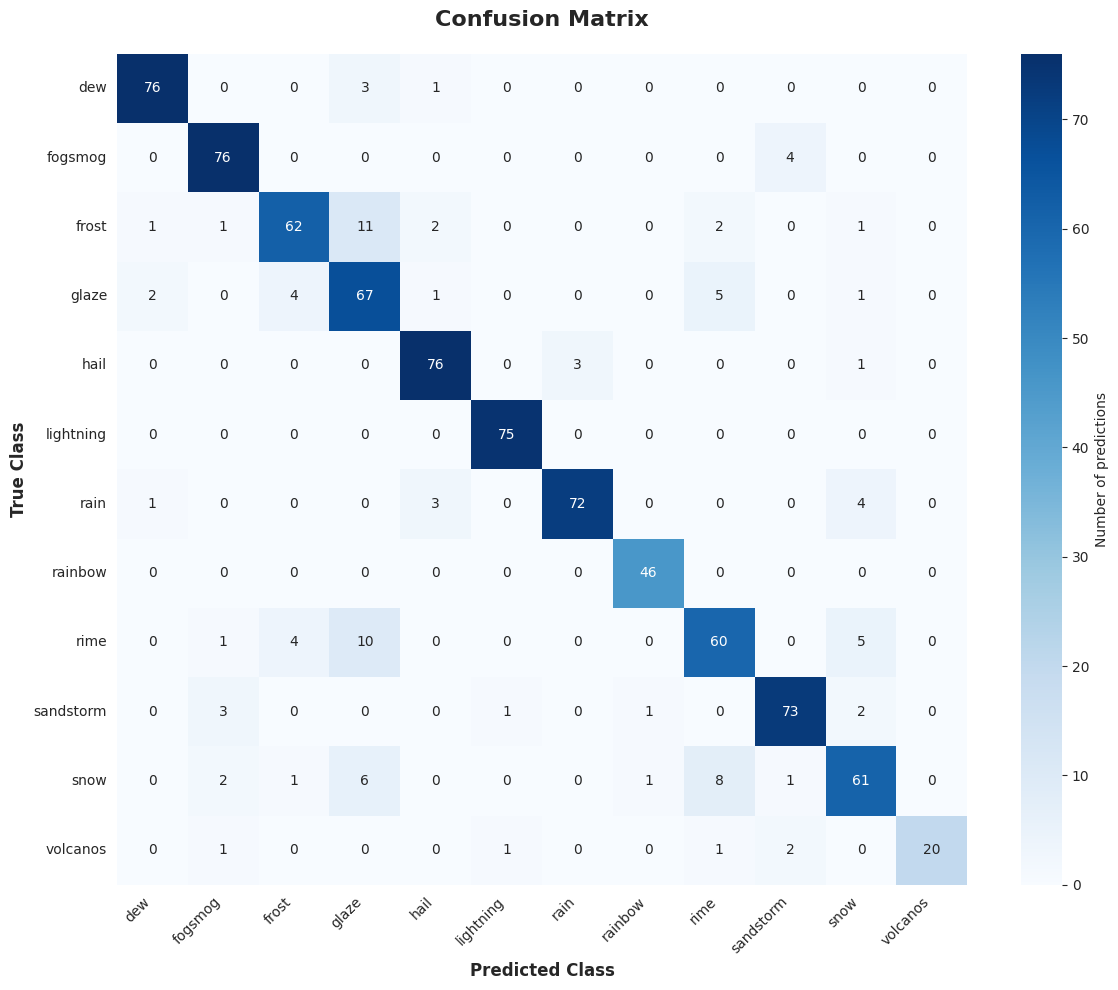

In [14]:
validation_generator.reset()
predictions = model.predict(validation_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = validation_generator.classes
class_labels = list(validation_generator.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels,
            cbar_kws={'label': 'Number of predictions'})
plt.title('Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Classification Report


In [15]:
report = classification_report(true_classes, predicted_classes,
                               target_names=class_labels,
                               digits=4)
print(report)

report_dict = classification_report(true_classes, predicted_classes,
                                    target_names=class_labels,
                                    output_dict=True)

df_report = pd.DataFrame(report_dict).transpose()
df_report = df_report.round(4)
print(df_report)

              precision    recall  f1-score   support

         dew     0.9500    0.9500    0.9500        80
     fogsmog     0.9048    0.9500    0.9268        80
       frost     0.8732    0.7750    0.8212        80
       glaze     0.6907    0.8375    0.7571        80
        hail     0.9157    0.9500    0.9325        80
   lightning     0.9740    1.0000    0.9868        75
        rain     0.9600    0.9000    0.9290        80
     rainbow     0.9583    1.0000    0.9787        46
        rime     0.7895    0.7500    0.7692        80
   sandstorm     0.9125    0.9125    0.9125        80
        snow     0.8133    0.7625    0.7871        80
    volcanos     1.0000    0.8000    0.8889        25

    accuracy                         0.8822       866
   macro avg     0.8952    0.8823    0.8867       866
weighted avg     0.8856    0.8822    0.8823       866

              precision  recall  f1-score   support
dew              0.9500  0.9500    0.9500   80.0000
fogsmog          0.9048  0.95

In [20]:
def extract_features_robust(model, generator):
    """
    Robust version for feature extraction
    """
    base_model = None
    for layer in model.layers:
        if hasattr(layer, 'layers'):
            base_model = layer
            break

    if base_model is None:
        base_model = model.layers[0]

    feature_extractor = keras.Model(
        inputs=base_model.input,
        outputs=base_model.output
    )

    generator.reset()
    features = []
    labels = []


    steps = len(generator)

    print("Extracting features...")
    for i in range(steps):
        x_batch, y_batch = next(generator)
        features_batch = feature_extractor.predict(x_batch, verbose=0)

        if len(features_batch.shape) == 4:
            features_batch = np.mean(features_batch, axis=(1, 2))

        features.append(features_batch)
        labels.append(np.argmax(y_batch, axis=1))

    features = np.vstack(features)
    labels = np.hstack(labels)

    print(f"✓ Features extracted: {features.shape}")
    return features, labels

features, labels = extract_features_robust(model, validation_generator)

Extracting features...
✓ Features extracted: (866, 1280)


## Feature Visualization by Class

Applying t-SNE for dimensionality reduction...
Number of samples: 866
Using perplexity: 30


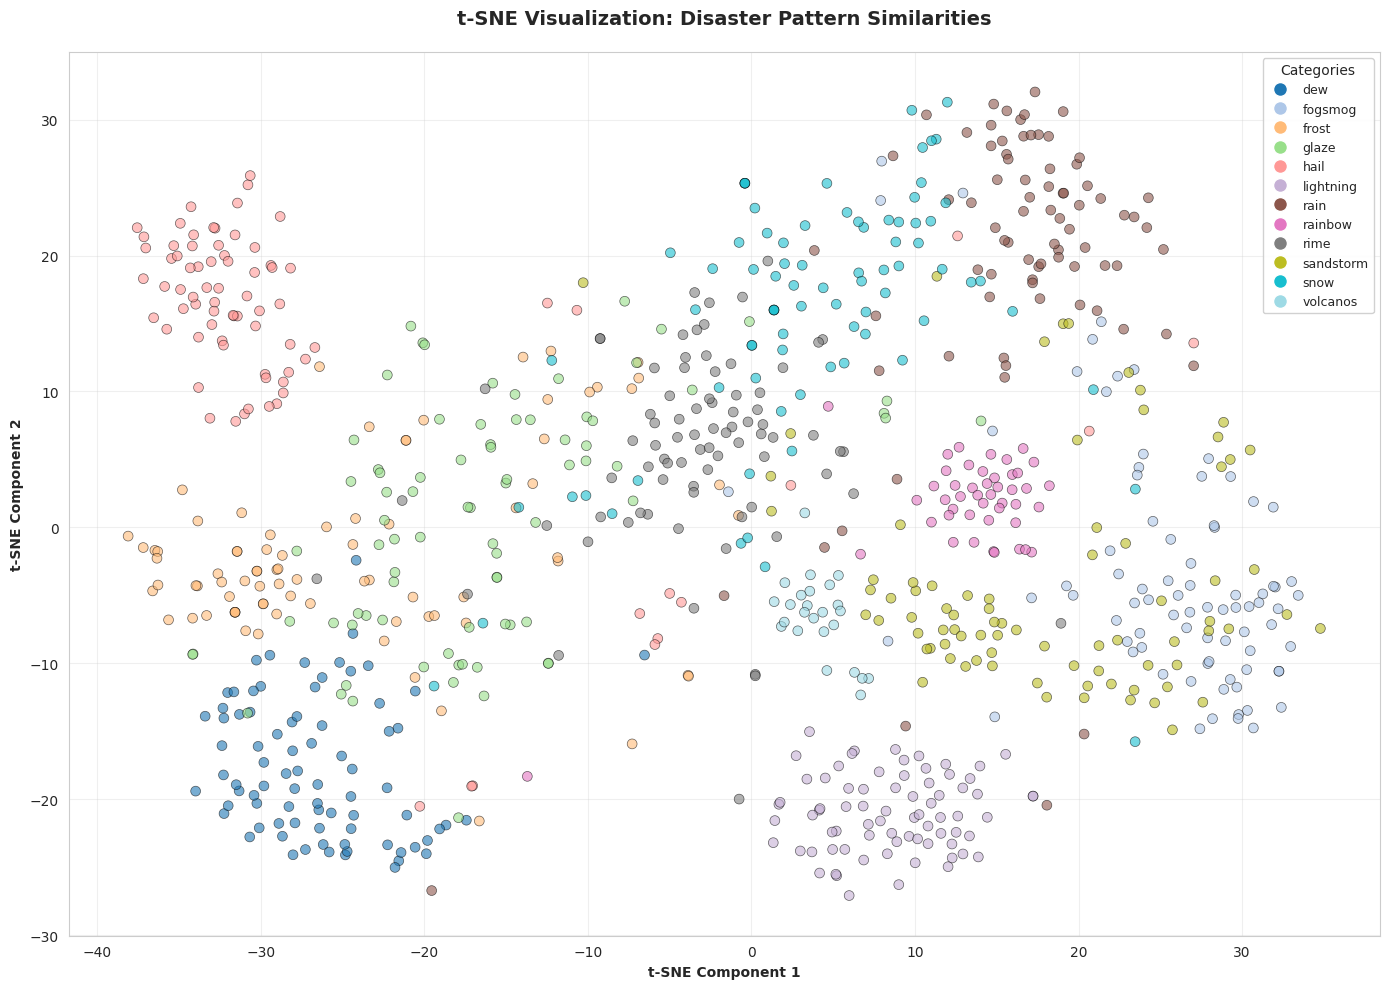


t-SNE INTERPRETATION
• Close points = similar visual patterns
• Well-separated clusters = model distinguishes classes well
• Mixed clusters = categories with similar characteristics


In [21]:
print("Applying t-SNE for dimensionality reduction...")
print(f"Number of samples: {features.shape[0]}")

n_samples = features.shape[0]
perplexity = min(30, n_samples - 1)

if n_samples < 50:
    perplexity = max(5, n_samples // 3)
elif n_samples < 100:
    perplexity = 10
elif n_samples < 200:
    perplexity = 15
else:
    perplexity = 30

print(f"Using perplexity: {perplexity}")

try:
    tsne = TSNE(n_components=2, random_state=CONFIG['SEED'],
                perplexity=perplexity, max_iter=1000)
    features_2d = tsne.fit_transform(features)

    plt.figure(figsize=(14, 10))
    scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1],
                         c=labels, cmap='tab20',
                         s=50, alpha=0.6, edgecolors='black', linewidth=0.5)

    handles = [plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=scatter.cmap(scatter.norm(i)),
                          markersize=10, label=class_labels[i])
               for i in range(len(class_labels))]
    plt.legend(handles=handles, title='Categories',
              loc='best', framealpha=0.9, fontsize=9)

    plt.title('t-SNE Visualization: Disaster Pattern Similarities',
             fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('t-SNE Component 1', fontweight='bold')
    plt.ylabel('t-SNE Component 2', fontweight='bold')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 60)
    print("t-SNE INTERPRETATION")
    print("=" * 60)
    print("• Close points = similar visual patterns")
    print("• Well-separated clusters = model distinguishes classes well")
    print("• Mixed clusters = categories with similar characteristics")
    print("=" * 60)

except Exception as e:
    print(f"t-SNE error: {e}")
    print("Trying PCA as alternative...")

    pca = PCA(n_components=2, random_state=CONFIG['SEED'])
    features_2d = pca.fit_transform(features)

    plt.figure(figsize=(14, 10))
    scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1],
                         c=labels, cmap='tab20',
                         s=50, alpha=0.6, edgecolors='black', linewidth=0.5)

    handles = [plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=scatter.cmap(scatter.norm(i)),
                          markersize=10, label=class_labels[i])
               for i in range(len(class_labels))]
    plt.legend(handles=handles, title='Categories',
              loc='best', framealpha=0.9, fontsize=9)

    plt.title('PCA Visualization: Disaster Pattern Similarities',
             fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Principal Component 1', fontweight='bold')
    plt.ylabel('Principal Component 2', fontweight='bold')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Variance explained by components: {pca.explained_variance_ratio_.sum():.2%}")
    print("PCA is a more stable alternative for visualization with few samples.")

## Average Distance Between Classes

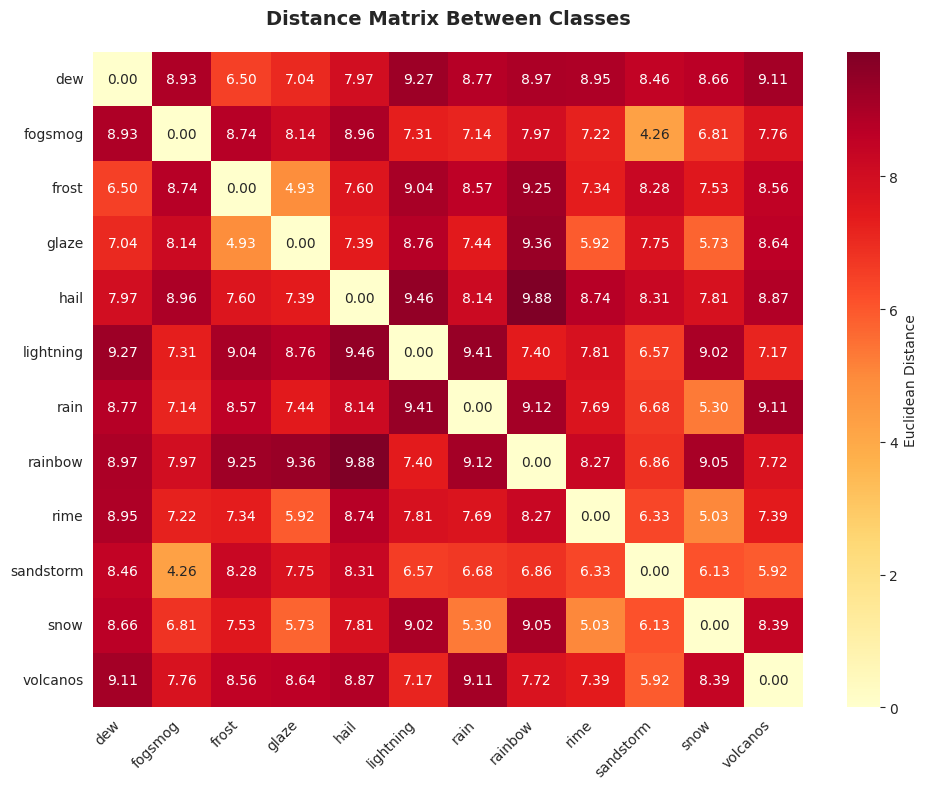


MOST SIMILAR CLASS PAIRS (smallest distance)
1. fogsmog ↔ sandstorm: 4.26
2. frost ↔ glaze: 4.93
3. rime ↔ snow: 5.03
4. rain ↔ snow: 5.30
5. glaze ↔ snow: 5.73

MOST DIFFERENT CLASS PAIRS (largest distance)
1. hail ↔ rainbow: 9.88
2. hail ↔ lightning: 9.46
3. lightning ↔ rain: 9.41
4. glaze ↔ rainbow: 9.36
5. dew ↔ lightning: 9.27


In [22]:
def analyze_class_distances(features, labels, class_labels):
    """
    Analyzes average distances between different classes
    """
    centroids = []
    for i in range(len(class_labels)):
        class_features = features[labels == i]
        if len(class_features) > 0:
            centroid = np.mean(class_features, axis=0)
            centroids.append(centroid)
        else:
            centroids.append(np.zeros(features.shape[1]))

    centroids = np.array(centroids)

    distance_matrix = cdist(centroids, centroids, metric='euclidean')

    plt.figure(figsize=(10, 8))
    sns.heatmap(distance_matrix, annot=True, fmt='.2f', cmap='YlOrRd',
                xticklabels=class_labels, yticklabels=class_labels,
                cbar_kws={'label': 'Euclidean Distance'})
    plt.title('Distance Matrix Between Classes',
             fontsize=14, fontweight='bold', pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 60)
    print("MOST SIMILAR CLASS PAIRS (smallest distance)")
    print("=" * 60)

    distances = []
    for i in range(len(class_labels)):
        for j in range(i + 1, len(class_labels)):
            distances.append((class_labels[i], class_labels[j], distance_matrix[i, j]))

    distances.sort(key=lambda x: x[2])

    for i, (class1, class2, dist) in enumerate(distances[:5], 1):
        print(f"{i}. {class1} ↔ {class2}: {dist:.2f}")

    print("\n" + "=" * 60)
    print("MOST DIFFERENT CLASS PAIRS (largest distance)")
    print("=" * 60)

    for i, (class1, class2, dist) in enumerate(distances[-5:][::-1], 1):
        print(f"{i}. {class1} ↔ {class2}: {dist:.2f}")

    print("=" * 60)

analyze_class_distances(features, labels, class_labels)

## Model Prediction Testing

In [37]:
def predict_image(model, img_path, class_labels, img_size=(224, 224), threshold=0.5):
    """
    Predicts image class and shows probabilities with threshold visualization.
    
    Args:
        model: Trained model
        img_path: Path to image
        class_labels: List of class names
        img_size: Image size for prediction
        threshold: Probability threshold to mark classes as active (default: 0.5)
    """
    img = keras.preprocessing.image.load_img(img_path, target_size=img_size)
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class = class_labels[predicted_class_idx]
    confidence = predictions[0][predicted_class_idx]
    
    # Find all classes that exceed threshold
    above_threshold = predictions[0] >= threshold
    active_classes = [class_labels[i] for i in range(len(class_labels)) if above_threshold[i]]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.imshow(img)
    ax1.axis('off')
    title_text = f'Top Prediction: {predicted_class}\nConfidence: {confidence:.2%}'
    if len(active_classes) > 0:
        title_text += f'\n\nActive Classes (≥{threshold:.0%}): {", ".join(active_classes)}'
    ax1.set_title(title_text, fontsize=11, fontweight='bold')

    # Color bars: green if above threshold, steelblue otherwise
    colors = ['green' if predictions[0][i] >= threshold else 'steelblue'
              for i in range(len(class_labels))]
    
    ax2.barh(class_labels, predictions[0] * 100, color=colors, edgecolor='black')
    ax2.set_xlabel('Probability (%)', fontweight='bold')
    ax2.set_title('Probability Distribution', fontweight='bold')
    ax2.grid(axis='x', alpha=0.3)
    
    # Add threshold line
    ax2.axvline(threshold * 100, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({threshold:.0%})')
    ax2.legend(loc='lower right')

    plt.tight_layout()
    plt.show()
    
    # Print summary
    print("\n" + "="*60)
    print(f"TOP PREDICTION: {predicted_class} ({confidence:.2%})")
    print("="*60)
    if len(active_classes) > 0:
        print(f"Classes above threshold ({threshold:.0%}):")
        for i, cls in enumerate(class_labels):
            if predictions[0][i] >= threshold:
                print(f"  • {cls}: {predictions[0][i]:.2%}")
    else:
        print(f"No classes exceed the threshold of {threshold:.0%}")
    print("="*60)

    return predicted_class, confidence, active_classes

In [38]:
def predict_random(threshold=0.5):
    """
    Predicts a random image from the dataset with threshold visualization.
    
    Args:
        threshold: Probability threshold for marking classes as active (default: 0.5)
    """
    random_category = np.random.choice(CATEGORIES)
    category_path = os.path.join(BASE_PATH, random_category)
    images = [f for f in os.listdir(category_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    random_image = np.random.choice(images)
    test_image_path = os.path.join(category_path, random_image)

    predicted_class, confidence, active_classes = predict_image(
        model,
        test_image_path,
        class_labels,
        CONFIG['IMG_SIZE'],
        threshold=threshold
    )
    
def predict_by_category(categoria, threshold=0.5):
    """
    Predicts a random image from a specific category with threshold visualization.
    
    Args:
        categoria: Category name to select image from
        threshold: Probability threshold for marking classes as active (default: 0.5)
    """
    if categoria not in CATEGORIES:
        print(f"Category '{categoria}' not found in dataset.")
        return

    category_path = os.path.join(BASE_PATH, categoria)
    images = [f for f in os.listdir(category_path)
              if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    random_image = np.random.choice(images)
    test_image_path = os.path.join(category_path, random_image)

    predicted_class, confidence, active_classes = predict_image(
        model,
        test_image_path,
        class_labels,
        CONFIG['IMG_SIZE'],
        threshold=threshold
    )

print("✓ Prediction functions ready!")
print("\nUsage examples:")
print("  predict_random()              # Uses default threshold=0.5")
print("  predict_random(threshold=0.3) # Lower threshold for more sensitive detection")
print("  predict_random(threshold=0.7) # Higher threshold for more confident detection")
print("\n  predict_by_category('volcanos', threshold=0.4)")

✓ Prediction functions ready!

Usage examples:
  predict_random()              # Uses default threshold=0.5
  predict_random(threshold=0.3) # Lower threshold for more sensitive detection
  predict_random(threshold=0.7) # Higher threshold for more confident detection

  predict_by_category('volcanos', threshold=0.4)


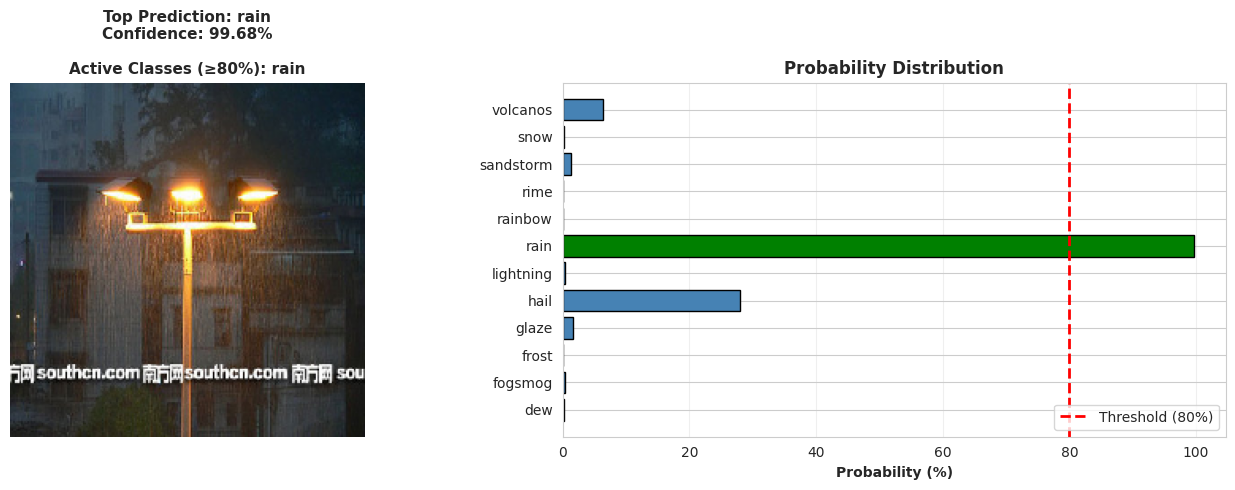


TOP PREDICTION: rain (99.68%)
Classes above threshold (80%):
  • rain: 99.68%


In [39]:
predict_random(threshold=CONFIG['THRESHOLD'])

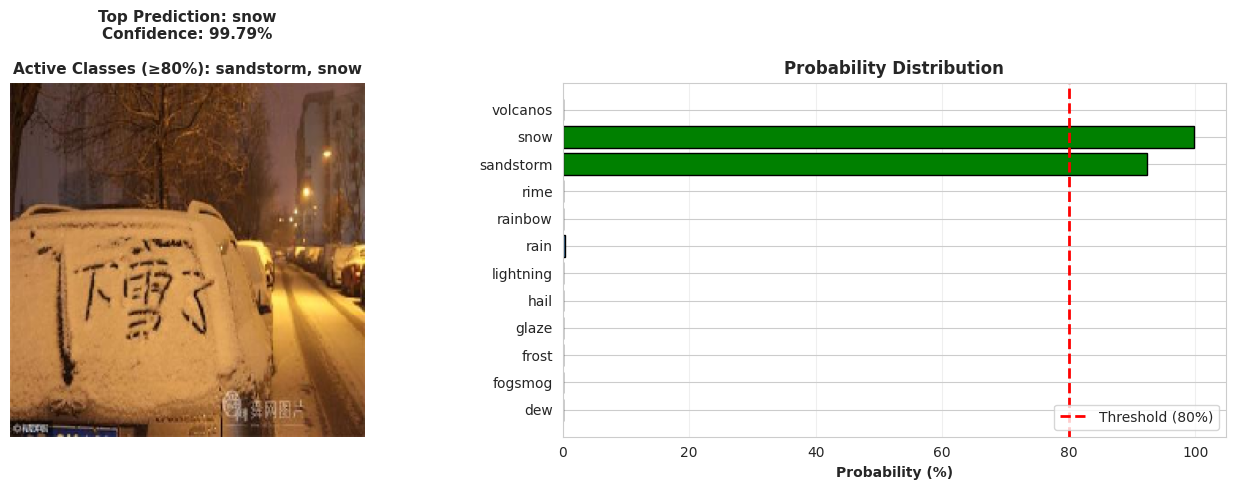


TOP PREDICTION: snow (99.79%)
Classes above threshold (80%):
  • sandstorm: 92.39%
  • snow: 99.79%


In [40]:
predict_random(threshold=CONFIG['THRESHOLD'])

Testing with threshold=0.4 for more multilabel detection:


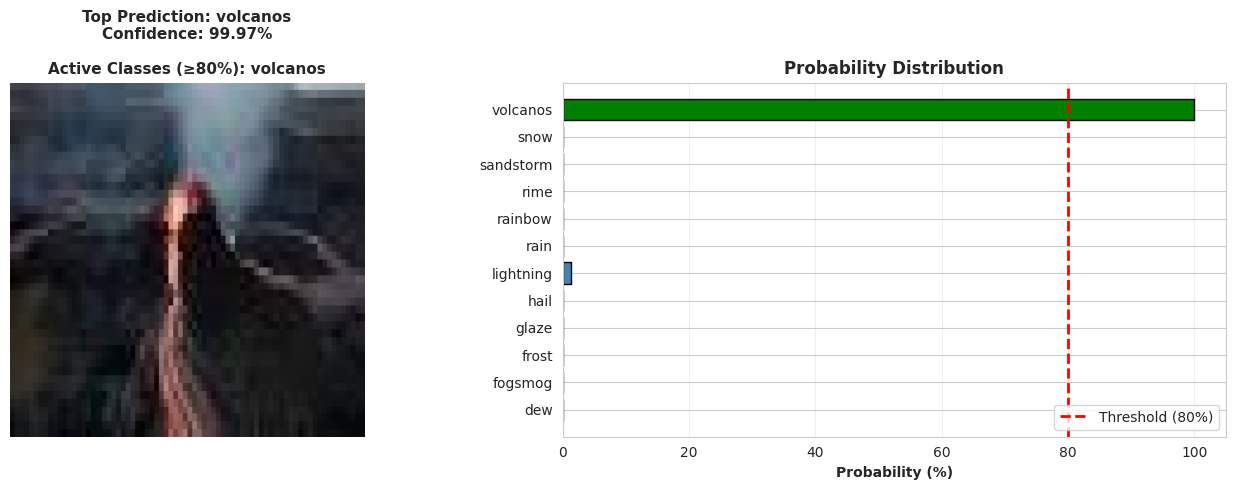


TOP PREDICTION: volcanos (99.97%)
Classes above threshold (80%):
  • volcanos: 99.97%


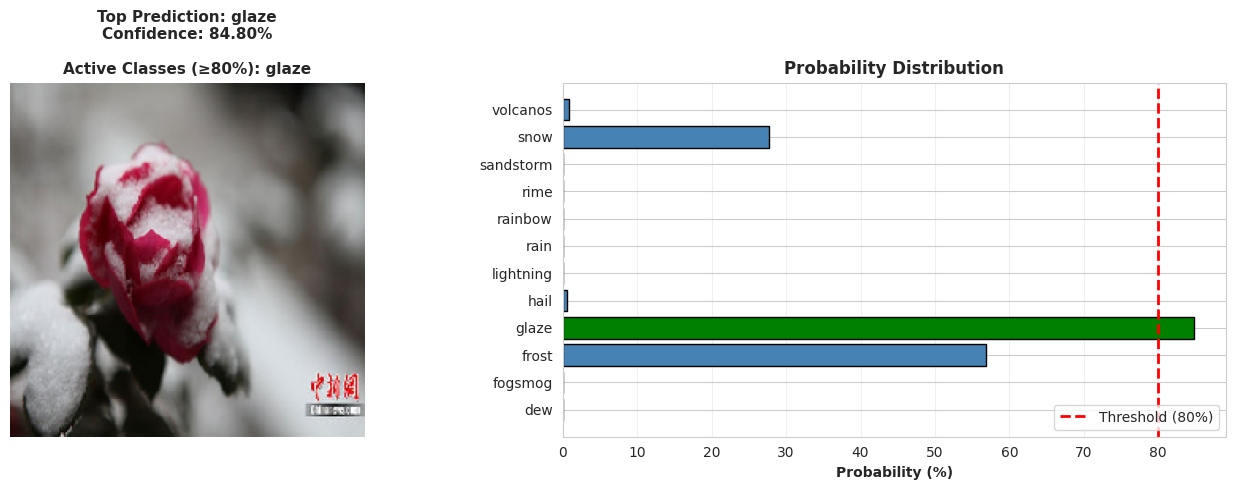


TOP PREDICTION: glaze (84.80%)
Classes above threshold (80%):
  • glaze: 84.80%


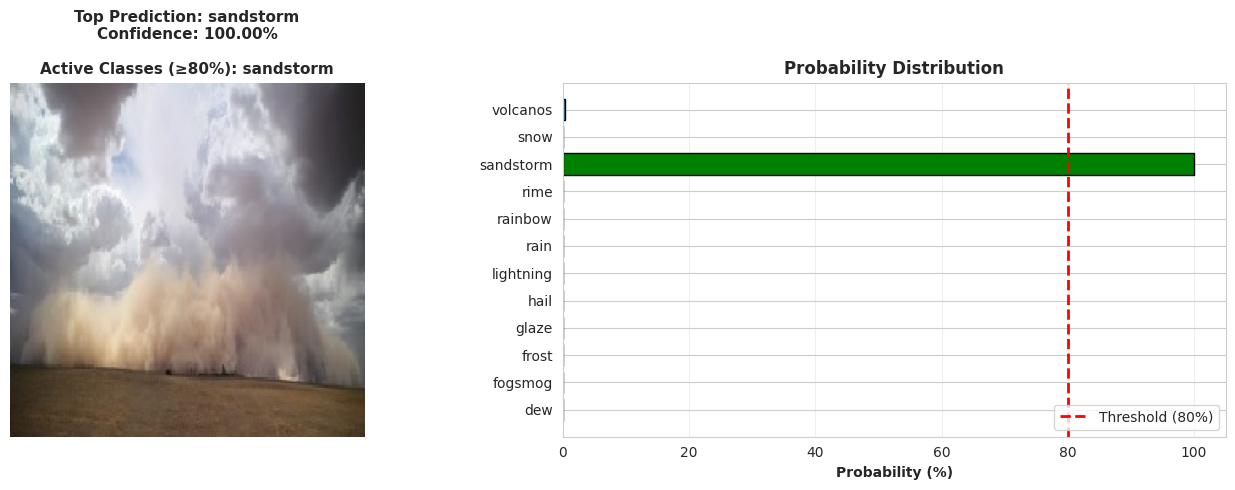


TOP PREDICTION: sandstorm (100.00%)
Classes above threshold (80%):
  • sandstorm: 100.00%


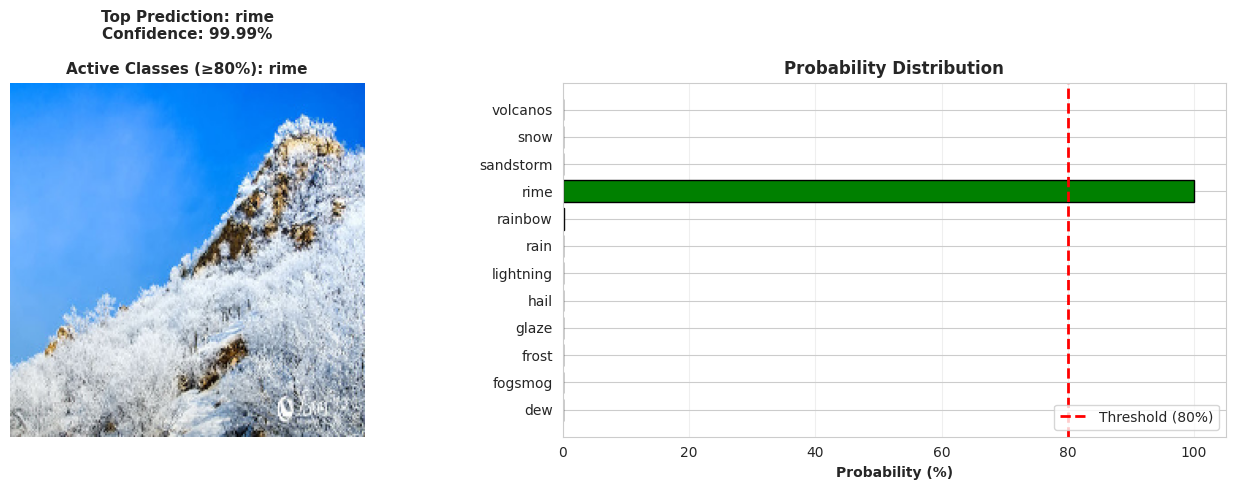


TOP PREDICTION: rime (99.99%)
Classes above threshold (80%):
  • rime: 99.99%


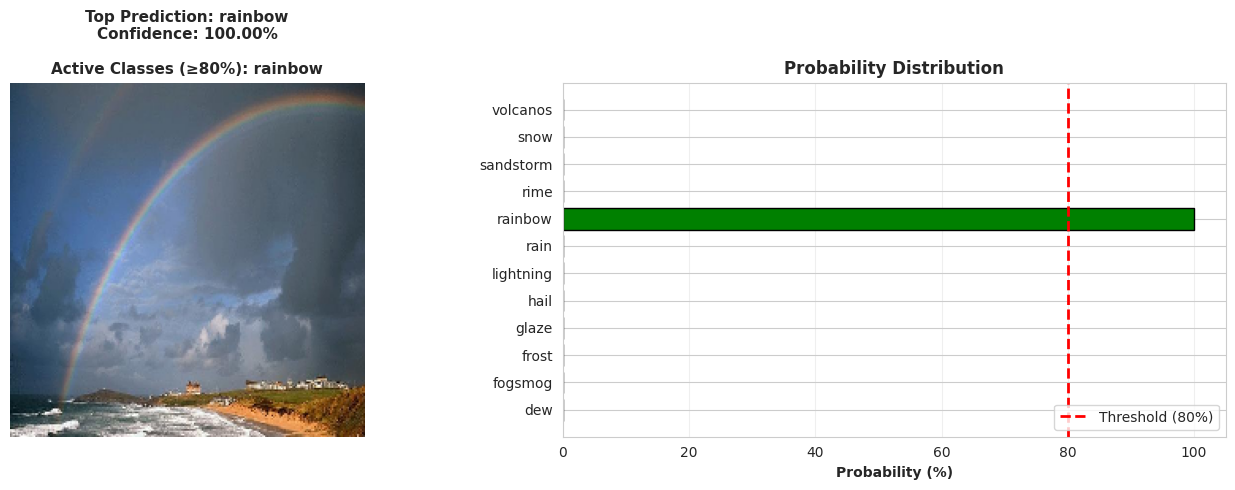


TOP PREDICTION: rainbow (100.00%)
Classes above threshold (80%):
  • rainbow: 100.00%


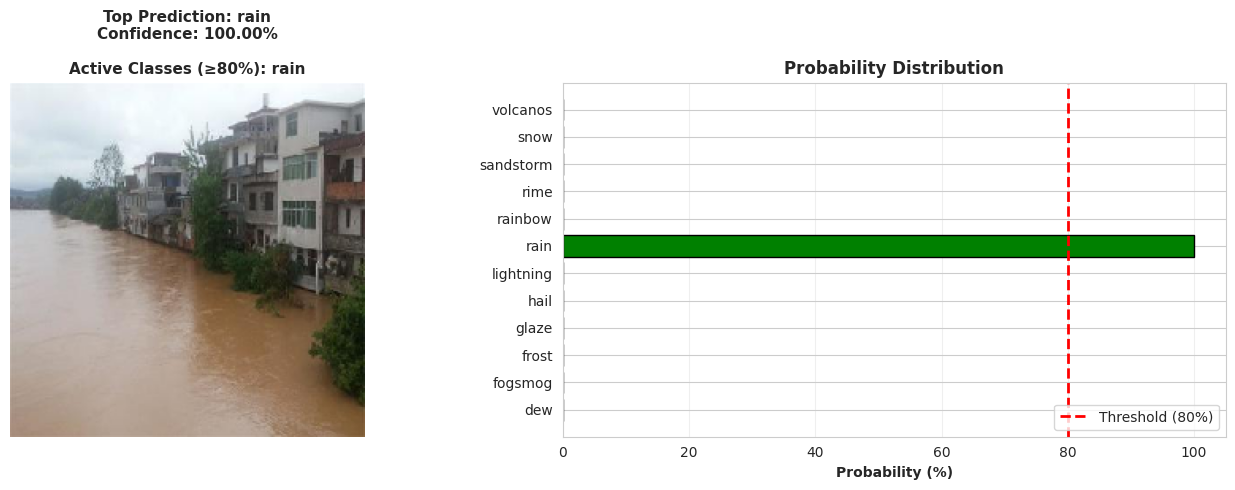


TOP PREDICTION: rain (100.00%)
Classes above threshold (80%):
  • rain: 100.00%


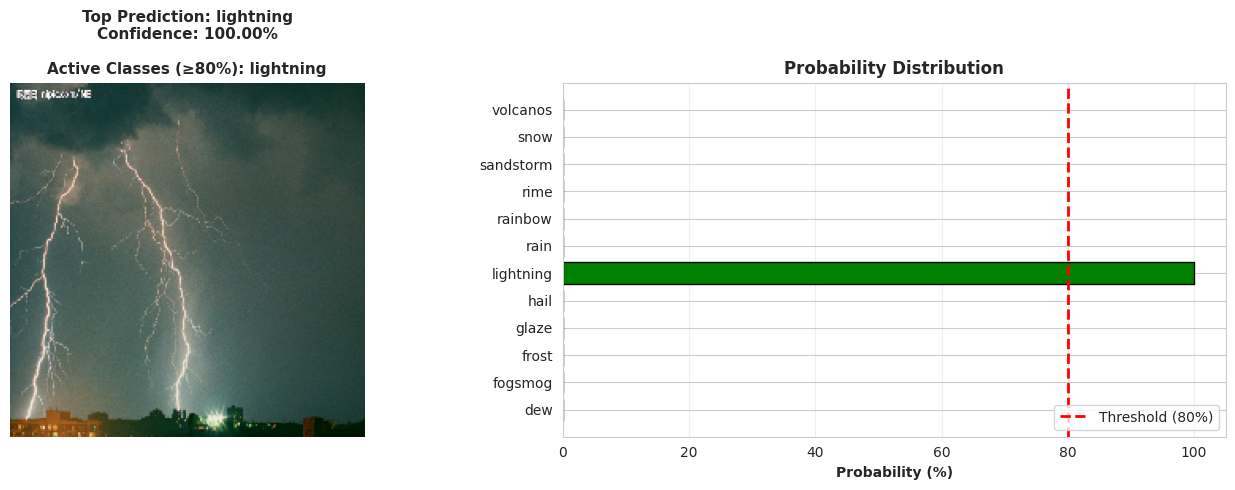


TOP PREDICTION: lightning (100.00%)
Classes above threshold (80%):
  • lightning: 100.00%


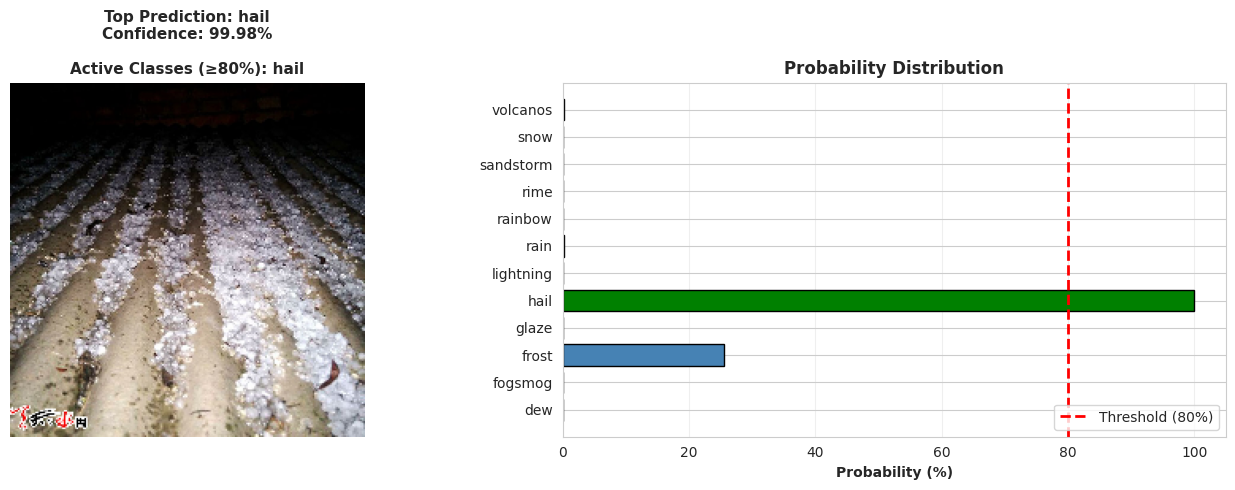


TOP PREDICTION: hail (99.98%)
Classes above threshold (80%):
  • hail: 99.98%


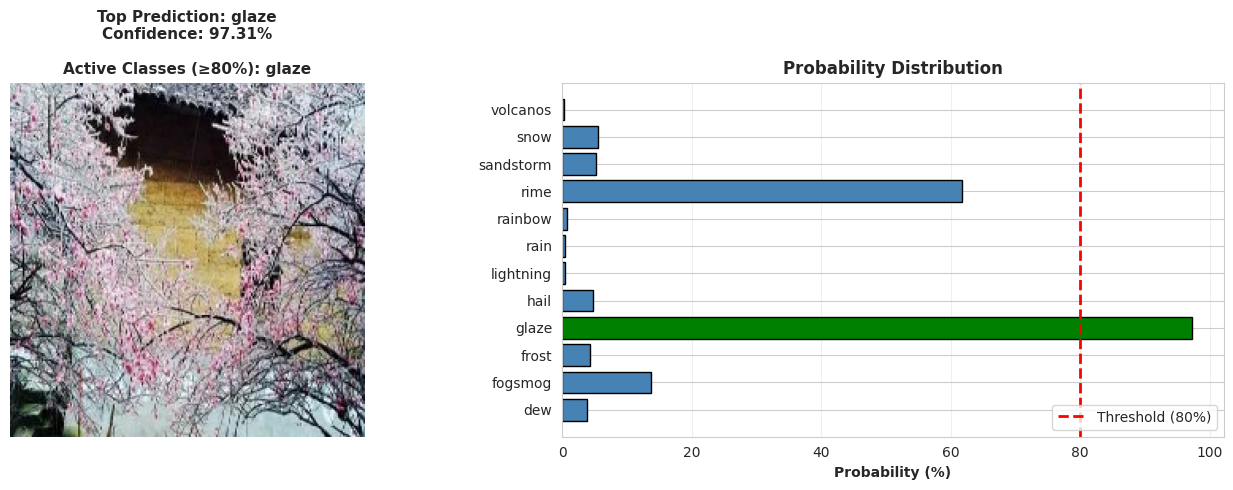


TOP PREDICTION: glaze (97.31%)
Classes above threshold (80%):
  • glaze: 97.31%


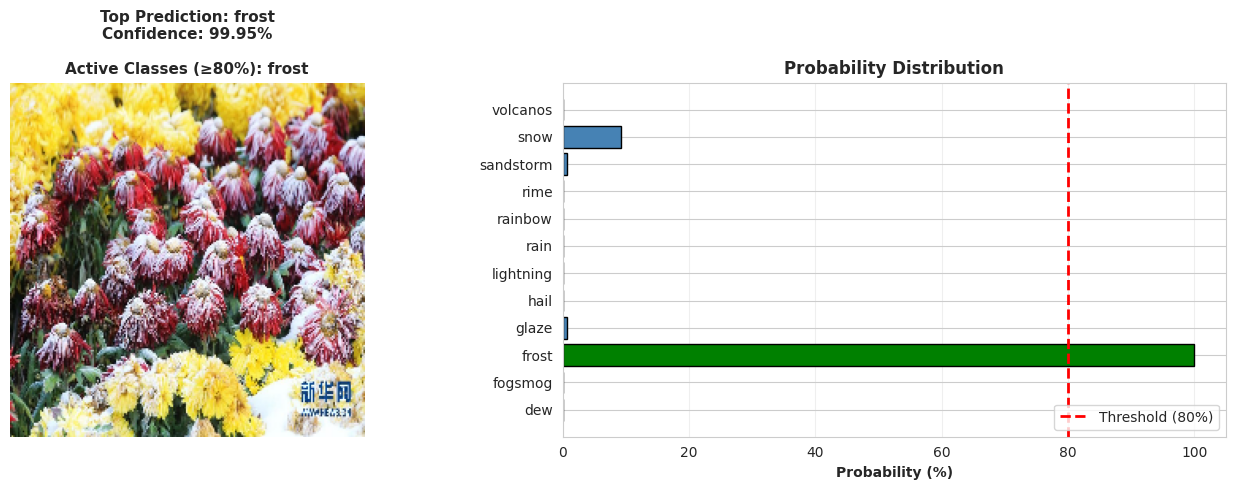


TOP PREDICTION: frost (99.95%)
Classes above threshold (80%):
  • frost: 99.95%


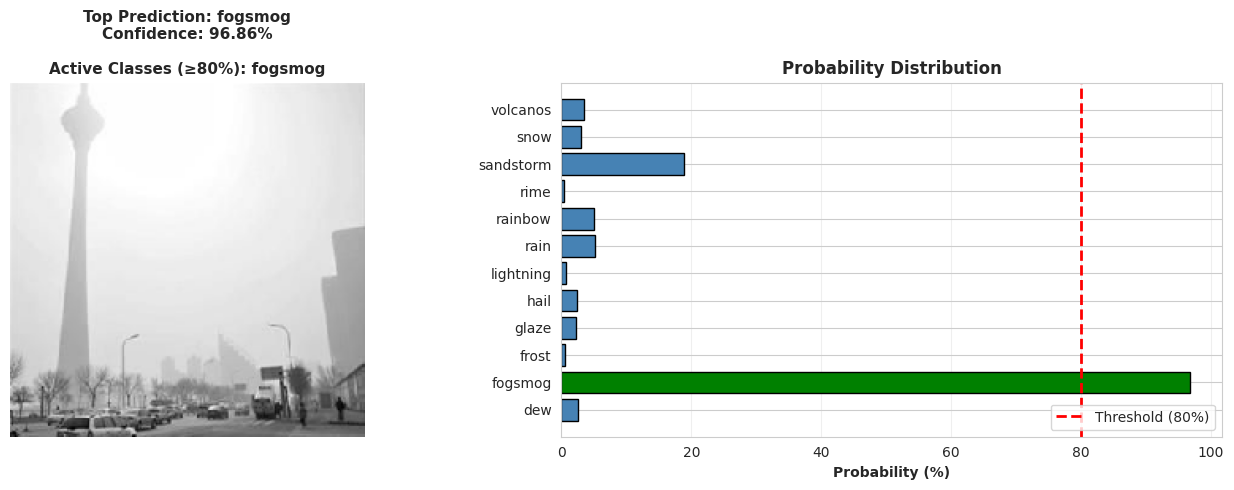


TOP PREDICTION: fogsmog (96.86%)
Classes above threshold (80%):
  • fogsmog: 96.86%


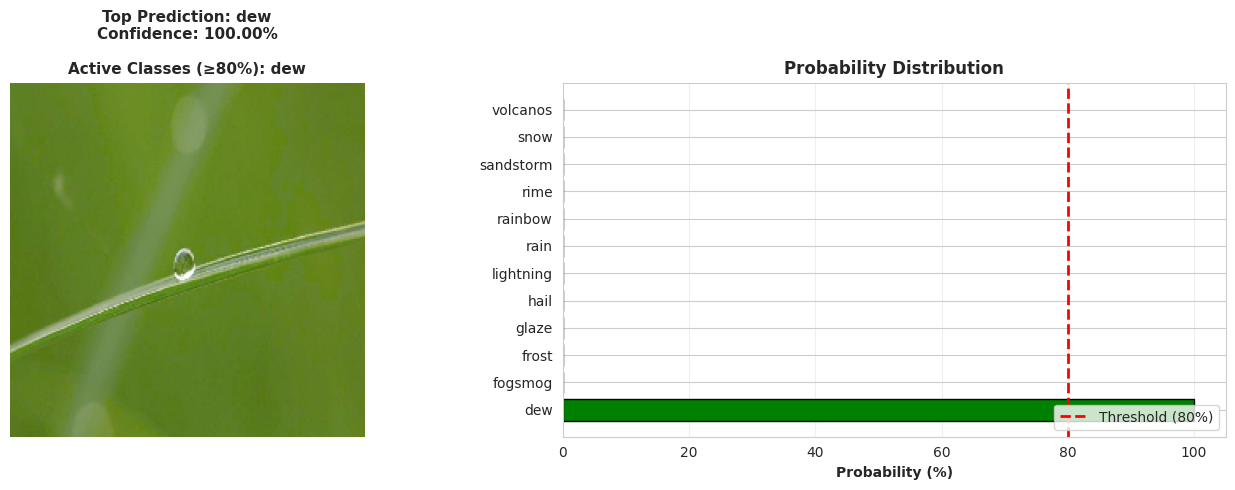


TOP PREDICTION: dew (100.00%)
Classes above threshold (80%):
  • dew: 100.00%


In [41]:
# Prediction examples by category with different thresholds
print("Testing with threshold=0.4 for more multilabel detection:")
predict_by_category('volcanos', threshold=CONFIG['THRESHOLD'])
predict_by_category('snow', threshold=CONFIG['THRESHOLD'])
predict_by_category('sandstorm', threshold=CONFIG['THRESHOLD'])
predict_by_category('rime', threshold=CONFIG['THRESHOLD'])
predict_by_category('rainbow', threshold=CONFIG['THRESHOLD'])
predict_by_category('rain', threshold=CONFIG['THRESHOLD'])
predict_by_category('lightning', threshold=CONFIG['THRESHOLD'])
predict_by_category('hail', threshold=CONFIG['THRESHOLD'])
predict_by_category('glaze', threshold=CONFIG['THRESHOLD'])
predict_by_category('frost', threshold=CONFIG['THRESHOLD'])
predict_by_category('fogsmog', threshold=CONFIG['THRESHOLD'])
predict_by_category('dew', threshold=CONFIG['THRESHOLD'])
    

In [42]:
def predict_external_image(model, img_path, threshold=0.5):
    """
    Predicts class of an external image with threshold visualization.
    
    Args:
        model: Trained model
        img_path: Path to external image
        threshold: Probability threshold for marking classes as active (default: 0.5)
    """
    if not os.path.exists(img_path):
        print(f"✗ Image does not exist: {img_path}")
        return

    predicted_class, confidence, active_classes = predict_image(
        model,
        img_path,
        class_labels,
        CONFIG['IMG_SIZE'],
        threshold=threshold
    )

print("✓ External image prediction function ready!")

✓ External image prediction function ready!


## External Image Predictions with Threshold

Testing the model on external images with multilabel scenarios. Using **threshold=0.3** to detect multiple phenomena in the same image.

**Threshold Visualization:**
- **Green bars**: Classes that exceed the threshold (active predictions)
- **Blue bars**: Classes below the threshold
- **Red dashed line**: Threshold value

**Threshold Guide:**
- Lower thresholds (e.g., 0.3): More sensitive, detects multiple classes (multilabel)
- Medium thresholds (e.g., 0.5): Balanced detection
- Higher thresholds (e.g., 0.7): More conservative, fewer predictions

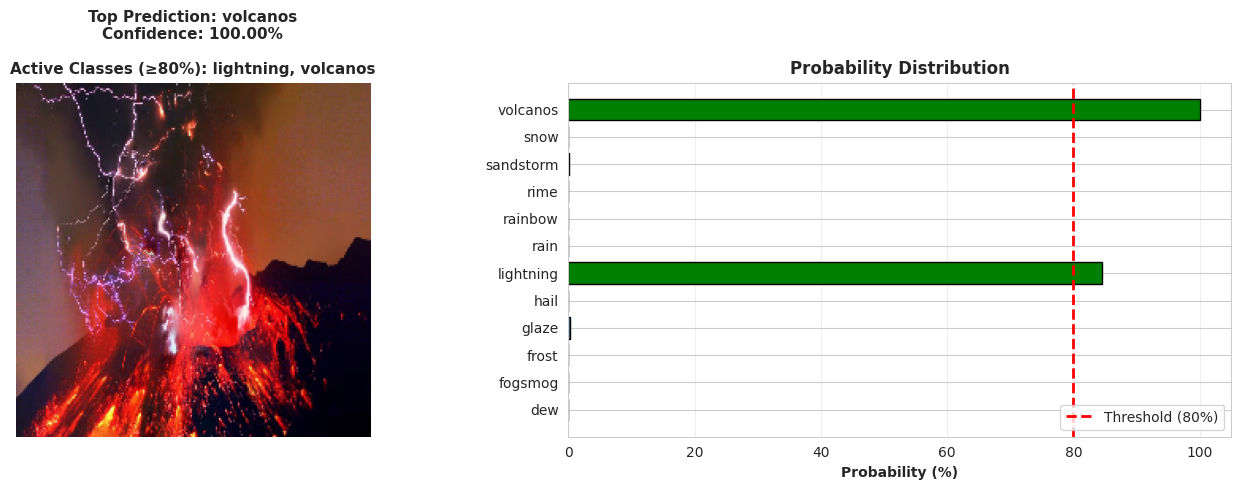


TOP PREDICTION: volcanos (100.00%)
Classes above threshold (80%):
  • lightning: 84.54%
  • volcanos: 100.00%


In [43]:
# Volcano + Lightning image (multilabel scenario)
external_image_path = MAIN_PATH+'/predict/volcano_lightning.jpeg'  
predict_external_image(model, external_image_path, threshold=CONFIG['THRESHOLD'])

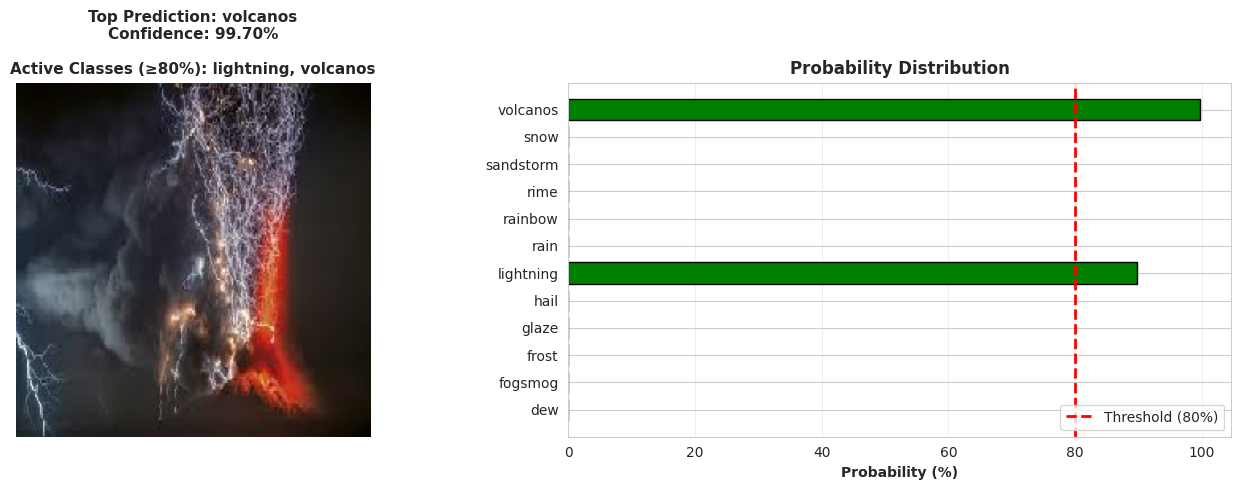


TOP PREDICTION: volcanos (99.70%)
Classes above threshold (80%):
  • lightning: 89.72%
  • volcanos: 99.70%


In [44]:
# Volcano + Lightning image 2 (multilabel scenario)
external_image_path = MAIN_PATH+'/predict/volcano_lightning_2.jpg'  
predict_external_image(model, external_image_path, threshold=CONFIG['THRESHOLD'])

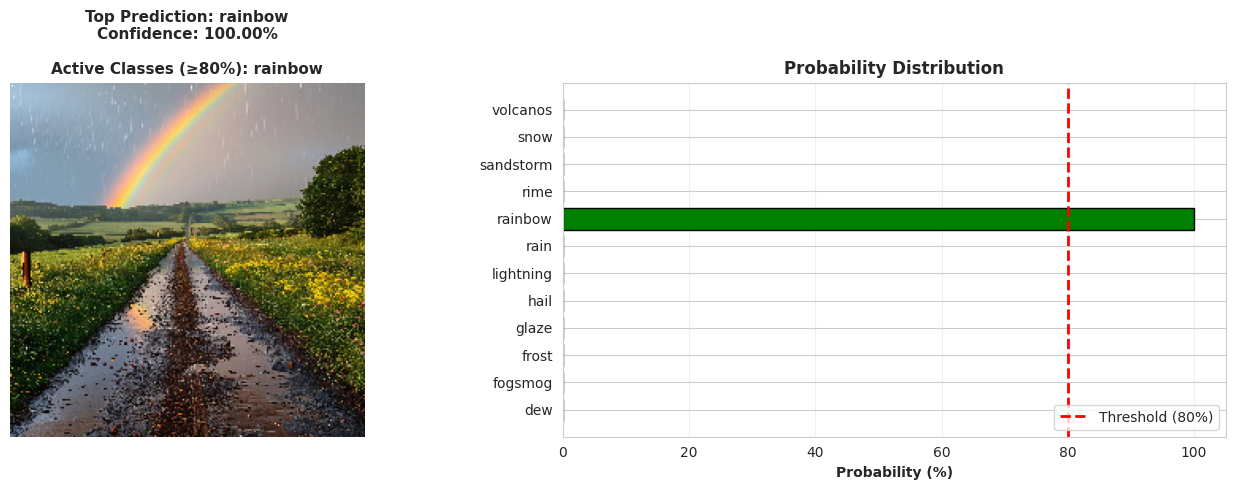


TOP PREDICTION: rainbow (100.00%)
Classes above threshold (80%):
  • rainbow: 100.00%


In [45]:
# Rainbow + Rain (multilabel scenario)
external_image_path = MAIN_PATH+'/predict/rainbow-rain.jpg'  
predict_external_image(model, external_image_path, threshold=CONFIG['THRESHOLD'])

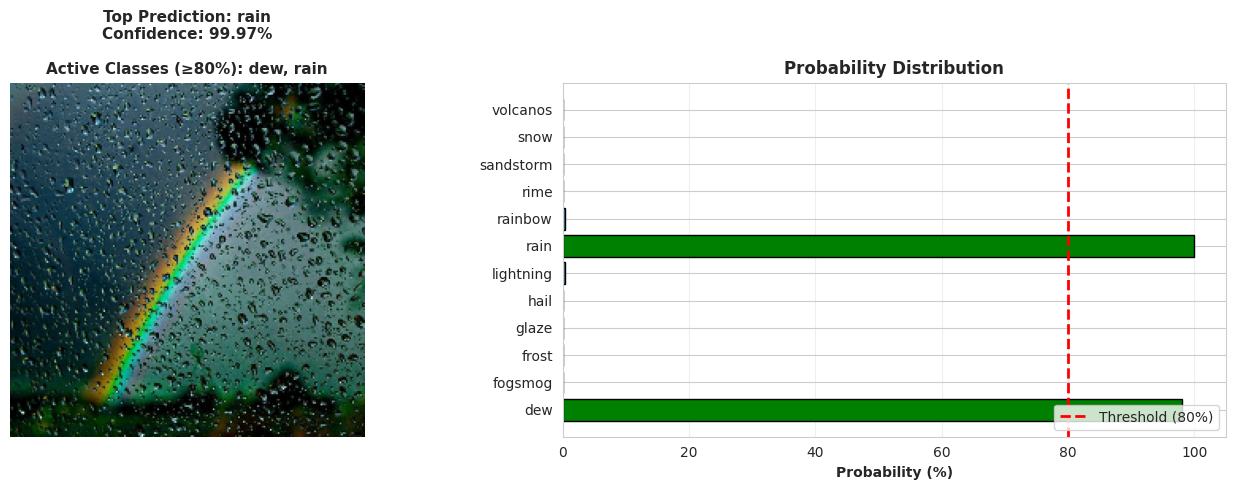


TOP PREDICTION: rain (99.97%)
Classes above threshold (80%):
  • dew: 98.06%
  • rain: 99.97%


In [46]:
# Rainbow + Rain 2 (multilabel scenario)
external_image_path = MAIN_PATH+'/predict/rainbow-rain-2.jpg'  
predict_external_image(model, external_image_path, threshold=CONFIG['THRESHOLD'])

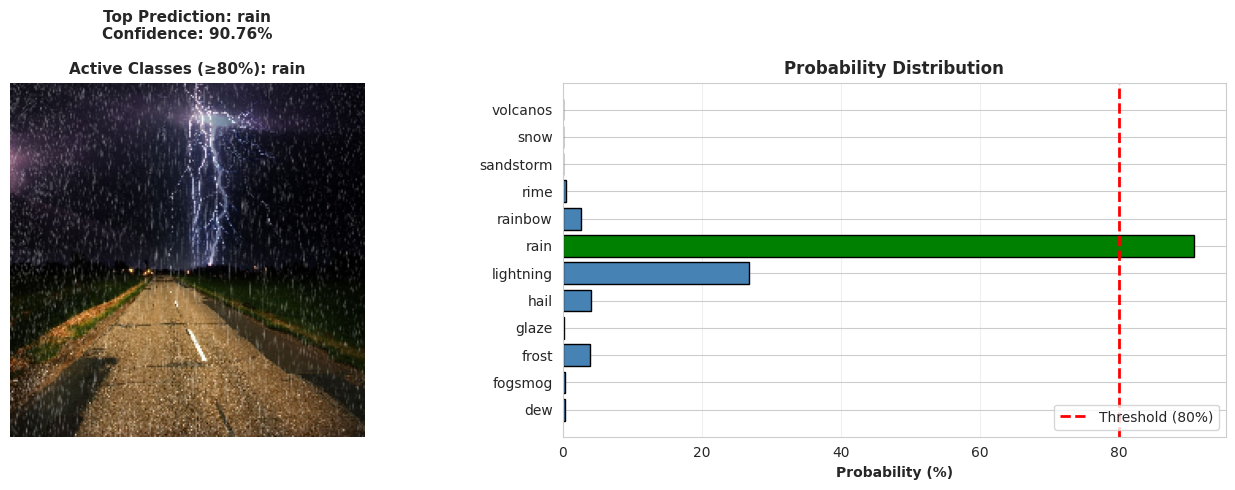


TOP PREDICTION: rain (90.76%)
Classes above threshold (80%):
  • rain: 90.76%


In [47]:
# Rain + Lightning (multilabel scenario)
external_image_path = MAIN_PATH+'/predict/rain-lightning.jpg' 
predict_external_image(model, external_image_path, threshold=CONFIG['THRESHOLD'])

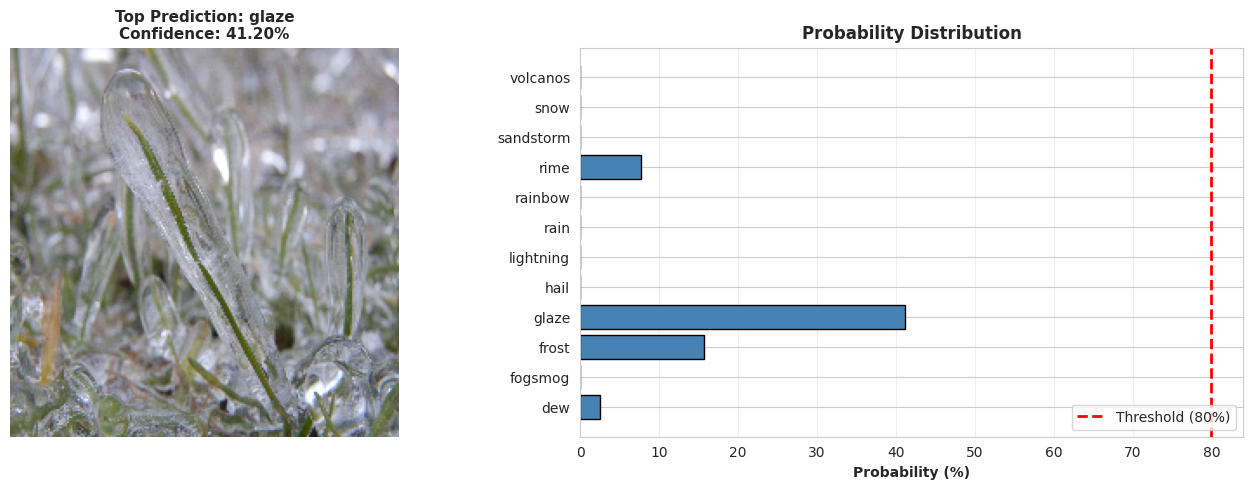


TOP PREDICTION: glaze (41.20%)
No classes exceed the threshold of 80%


In [48]:
# Glaze (single class)
external_image_path = MAIN_PATH+'/predict/glaze.jpg' 
predict_external_image(model, external_image_path, threshold=CONFIG['THRESHOLD'])